<a href="https://colab.research.google.com/github/fathazn/FORUM_DL/blob/main/forum_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**SET UP**

In [1]:
# Import
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
# load dataset
transform = transforms.ToTensor()

full_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 404kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.85MB/s]


In [3]:
# train dataset
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(full_dataset,[train_size, val_size])

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

48000
12000
10000


In [4]:
# dataloader
batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

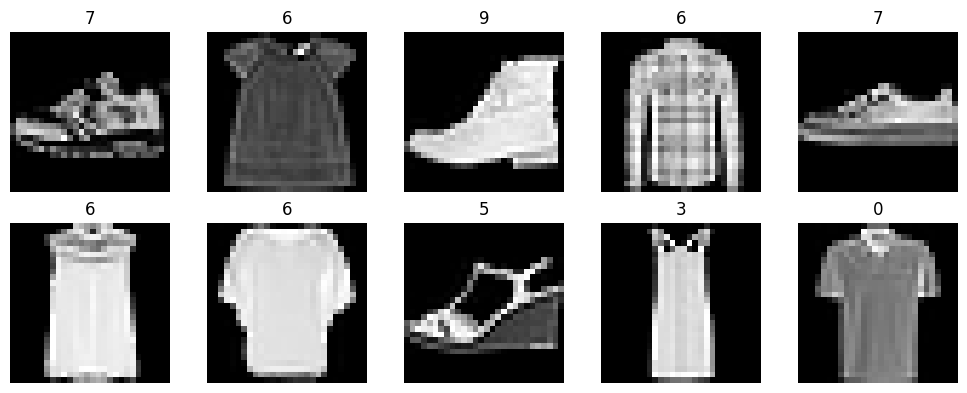

In [5]:
# visualisasi
images, labels = next(iter(train_loader))

plt.figure(figsize=(10,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(labels[i].item())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
class_names = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

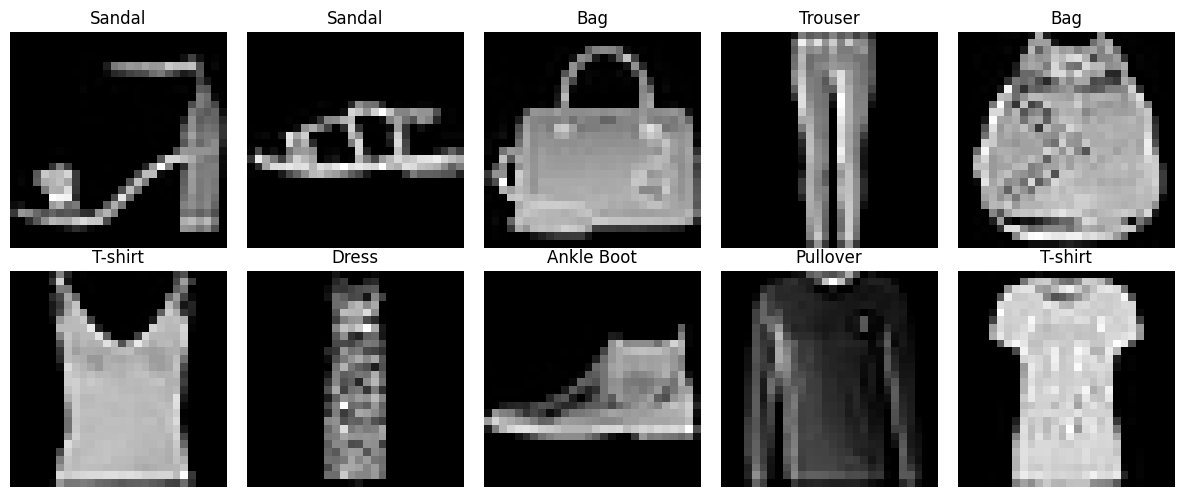

In [7]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Vanilla Autoencoder**

In [8]:
# buat model ae
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        x_hat = x_hat.view(-1, 1, 28, 28)

        return x_hat

In [9]:
# inisialisasi model
latent_dim = 64

ae = Autoencoder(latent_dim=latent_dim).to(device)

print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [10]:
criterion = nn.MSELoss()

optimizer = optim.Adam(ae.parameters(), lr=1e-3)

In [11]:
def train_autoencoder(model, train_loader, optimizer, criterion):
    model.train()
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)
        outputs = model(images)
        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(train_loader)

In [12]:
def validate_autoencoder(model,val_loader,criterion):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            outputs = model(images)
            loss = criterion(outputs, images)
            total_loss += loss.item()

    return total_loss / len(val_loader)

In [13]:
num_epochs = 20

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    train_loss = train_autoencoder(ae, train_loader, optimizer, criterion)
    val_loss = validate_autoencoder(ae, val_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

Epoch 1/20 | Train Loss: 0.04123 | Val Loss: 0.02410
Epoch 2/20 | Train Loss: 0.02195 | Val Loss: 0.02041
Epoch 3/20 | Train Loss: 0.01900 | Val Loss: 0.01823
Epoch 4/20 | Train Loss: 0.01738 | Val Loss: 0.01676
Epoch 5/20 | Train Loss: 0.01607 | Val Loss: 0.01567
Epoch 6/20 | Train Loss: 0.01511 | Val Loss: 0.01490
Epoch 7/20 | Train Loss: 0.01434 | Val Loss: 0.01420
Epoch 8/20 | Train Loss: 0.01368 | Val Loss: 0.01355
Epoch 9/20 | Train Loss: 0.01316 | Val Loss: 0.01307
Epoch 10/20 | Train Loss: 0.01269 | Val Loss: 0.01265
Epoch 11/20 | Train Loss: 0.01233 | Val Loss: 0.01226
Epoch 12/20 | Train Loss: 0.01199 | Val Loss: 0.01211
Epoch 13/20 | Train Loss: 0.01172 | Val Loss: 0.01183
Epoch 14/20 | Train Loss: 0.01143 | Val Loss: 0.01148
Epoch 15/20 | Train Loss: 0.01118 | Val Loss: 0.01127
Epoch 16/20 | Train Loss: 0.01094 | Val Loss: 0.01118
Epoch 17/20 | Train Loss: 0.01071 | Val Loss: 0.01083
Epoch 18/20 | Train Loss: 0.01051 | Val Loss: 0.01062
Epoch 19/20 | Train Loss: 0.01033 | V

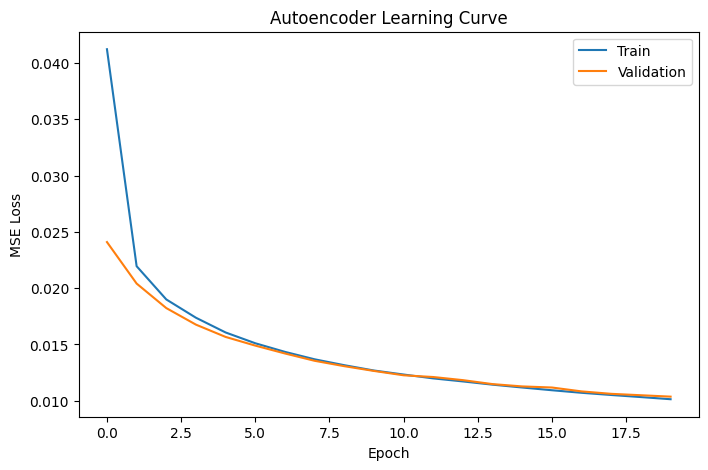

In [14]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Learning Curve")
plt.legend()
plt.show()

In [15]:
ae.eval()
images, _ = next(iter(test_loader))
images = images.to(device)
with torch.no_grad():
    reconstructed = ae(images)

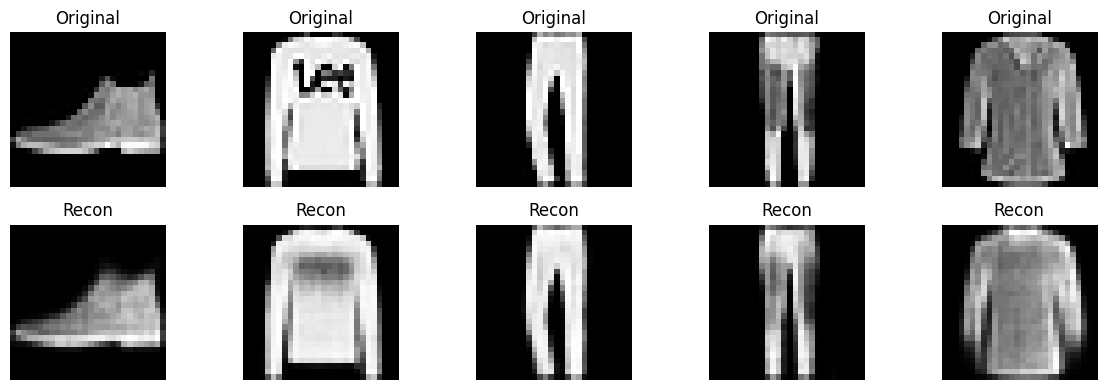

In [16]:
plt.figure(figsize=(12,4))

for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("Original")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("Recon")

plt.tight_layout()
plt.show()

In [17]:
torch.save(ae.state_dict(), "vanilla_autoencoder.pth")

print("Model saved!")

Model saved!


**Sparse Autoencoder**

In [21]:
class SparseAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        reconstruction = reconstruction.view(-1, 1, 28, 28)

        return reconstruction, latent

In [22]:
sae = SparseAutoencoder(latent_dim=64).to(device)

print(sae)

SparseAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [23]:
criterion = nn.MSELoss()

optimizer_sae = optim.Adam(sae.parameters(),lr=1e-3)

In [24]:
def sparsity_penalty(latent):
    return torch.mean(torch.abs(latent))

In [25]:
def train_sparse_autoencoder(model, dataloader, optimizer, beta=1e-3):
    model.train()
    total_loss = 0

    for images, _ in dataloader:
        images = images.to(device)
        outputs, latent = model(images)
        reconstruction_loss = criterion(outputs, images)
        sparse_loss = sparsity_penalty(latent)

        loss = (reconstruction_loss + beta * sparse_loss)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(dataloader)

In [26]:
def validate_sparse_autoencoder(model, dataloader, beta=1e-3):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(device)
            outputs, latent = model(images)
            reconstruction_loss = criterion(outputs, images)
            sparse_loss = sparsity_penalty(latent)

            loss = (reconstruction_loss + beta * sparse_loss)

            total_loss += loss.item()

    return total_loss / len(dataloader)

In [27]:
epochs = 20

sae_train_losses = []
sae_val_losses = []

for epoch in range(epochs):

    train_loss = train_sparse_autoencoder(sae, train_loader, optimizer_sae)

    val_loss = validate_sparse_autoencoder(sae, val_loader)

    sae_train_losses.append(train_loss)
    sae_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train: {train_loss:.5f} "
        f"Val: {val_loss:.5f}"
    )

Epoch [1/20] Train: 0.04161 Val: 0.02353
Epoch [2/20] Train: 0.02112 Val: 0.01948
Epoch [3/20] Train: 0.01828 Val: 0.01762
Epoch [4/20] Train: 0.01667 Val: 0.01618
Epoch [5/20] Train: 0.01555 Val: 0.01534
Epoch [6/20] Train: 0.01477 Val: 0.01470
Epoch [7/20] Train: 0.01407 Val: 0.01392
Epoch [8/20] Train: 0.01344 Val: 0.01351
Epoch [9/20] Train: 0.01294 Val: 0.01296
Epoch [10/20] Train: 0.01246 Val: 0.01253
Epoch [11/20] Train: 0.01207 Val: 0.01206
Epoch [12/20] Train: 0.01171 Val: 0.01168
Epoch [13/20] Train: 0.01137 Val: 0.01152
Epoch [14/20] Train: 0.01113 Val: 0.01120
Epoch [15/20] Train: 0.01086 Val: 0.01094
Epoch [16/20] Train: 0.01067 Val: 0.01079
Epoch [17/20] Train: 0.01045 Val: 0.01057
Epoch [18/20] Train: 0.01028 Val: 0.01039
Epoch [19/20] Train: 0.01007 Val: 0.01026
Epoch [20/20] Train: 0.00992 Val: 0.01009


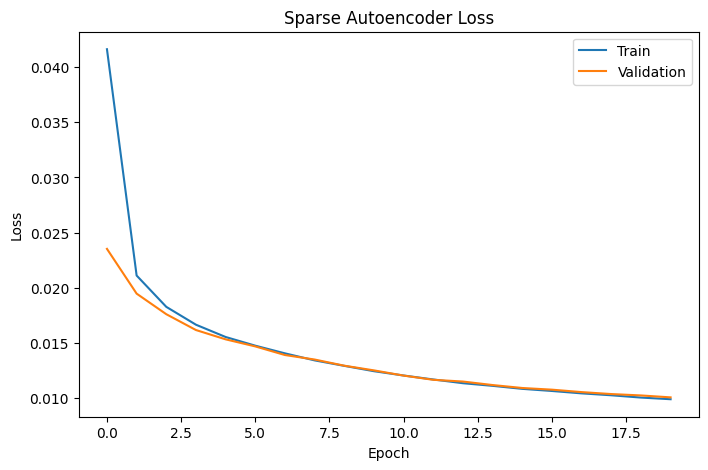

In [28]:
plt.figure(figsize=(8,5))
plt.plot(sae_train_losses,label="Train")
plt.plot(sae_val_losses,label="Validation")
plt.title("Sparse Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [29]:
sae.eval()

images, _ = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
  reconstructed, latent = sae(images)

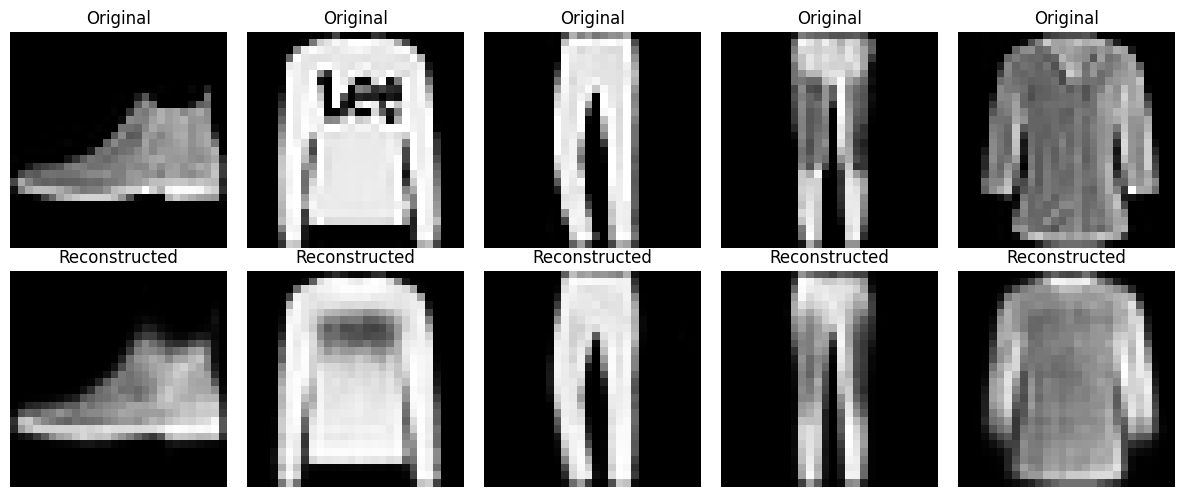

In [30]:
plt.figure(figsize=(12,5))

for i in range(5):

    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

**VAE**

In [31]:
class VAE(nn.Module):

    def __init__(self, latent_dim=64):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(128,latent_dim)

        self.fc_logvar = nn.Linear(128,latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decoder(z)
        reconstruction = reconstruction.view(-1, 1, 28, 28)

        return (reconstruction, mu, logvar)

In [32]:
latent_dim = 64

vae = VAE(latent_dim=latent_dim).to(device)

print(vae)

optimizer_vae = optim.Adam(vae.parameters(),lr=1e-3)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [33]:
def vae_loss(reconstruction, original, mu, logvar):
    reconstruction_loss = nn.functional.mse_loss(reconstruction, original, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return reconstruction_loss + kl_loss

In [34]:
def train_va(model, dataloader,optimizer):
    model.train()
    total_loss = 0
    for images, _ in dataloader:
        images = images.to(device)
        optimizer.zero_grad()
        reconstruction, mu, logvar = model(images)
        loss = vae_loss(reconstruction, images, mu, logvar)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

In [35]:
def validate_vae(model, dataloader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(device)
            reconstruction, mu, logvar = model(images)
            loss = vae_loss(reconstruction, images, mu, logvar)
            total_loss += loss.item()
    return total_loss / len(dataloader.dataset)

In [36]:
epoch = 20

vae_train_losses = []
vae_val_losses = []

for epoch in range(epoch):
    train_loss = train_va(vae, train_loader, optimizer_vae)
    val_loss = validate_vae(vae, val_loader)
    vae_train_losses.append(train_loss)
    vae_val_losses.append(val_loss)
    print(f"Epoch [{epoch+1}/{epoch}] Train: {train_loss:.5f} Val: {val_loss:.5f}")

Epoch [1/0] Train: 6289.23135 Val: 38.78919
Epoch [2/1] Train: 4404.02192 Val: 31.52290
Epoch [3/2] Train: 3822.30140 Val: 28.89039
Epoch [4/3] Train: 3561.88978 Val: 27.10056
Epoch [5/4] Train: 3408.88922 Val: 26.52858
Epoch [6/5] Train: 3335.37224 Val: 25.95489
Epoch [7/6] Train: 3286.88589 Val: 25.58111
Epoch [8/7] Train: 3248.06346 Val: 25.40201
Epoch [9/8] Train: 3216.97722 Val: 25.13203
Epoch [10/9] Train: 3198.99542 Val: 25.07188
Epoch [11/10] Train: 3177.70611 Val: 25.00618
Epoch [12/11] Train: 3158.85045 Val: 24.78297
Epoch [13/12] Train: 3147.72385 Val: 24.67379
Epoch [14/13] Train: 3135.11861 Val: 24.57339
Epoch [15/14] Train: 3124.69530 Val: 24.62998
Epoch [16/15] Train: 3115.04634 Val: 24.65644
Epoch [17/16] Train: 3107.31774 Val: 24.47183
Epoch [18/17] Train: 3098.83372 Val: 24.32598
Epoch [19/18] Train: 3087.00890 Val: 24.22059
Epoch [20/19] Train: 3075.15841 Val: 24.19012


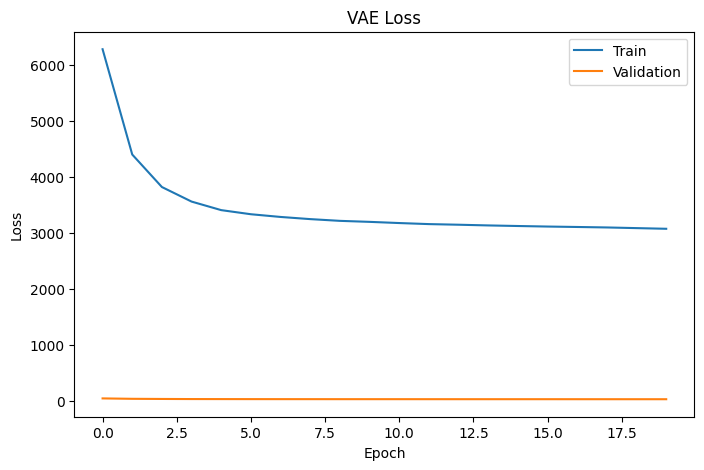

In [37]:
plt.figure(figsize=(8,5))
plt.plot(vae_train_losses,label="Train")
plt.plot(vae_val_losses,label="Validation")
plt.title("VAE Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [38]:
vae.eval()
images, _ = next(iter(test_loader))
images = images.to(device)
with torch.no_grad():
    reconstruction, mu, logvar = vae(images)

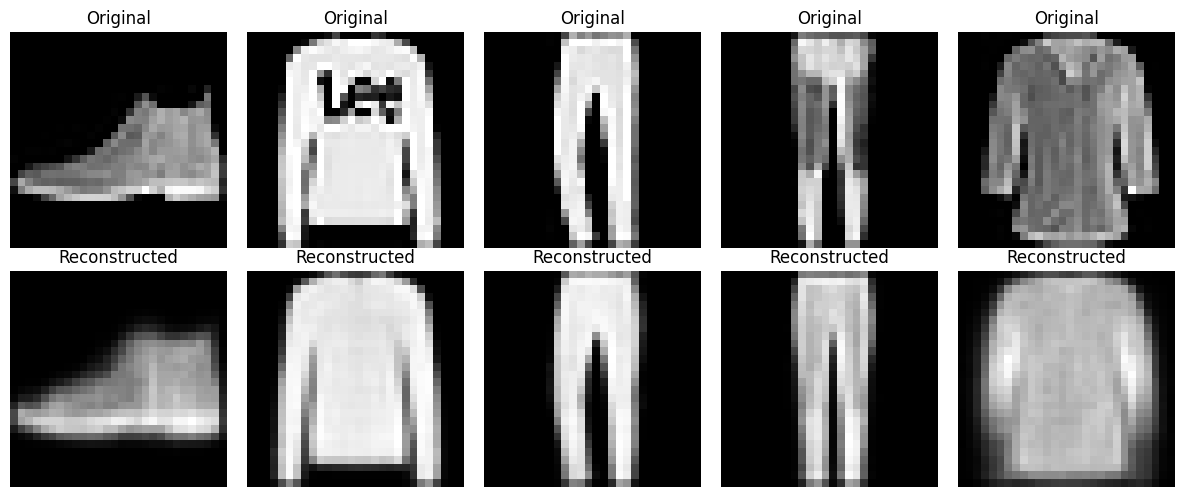

In [39]:
plt.figure(figsize=(12,5))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstruction[i].cpu().squeeze(), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")
plt.tight_layout()
plt.show()

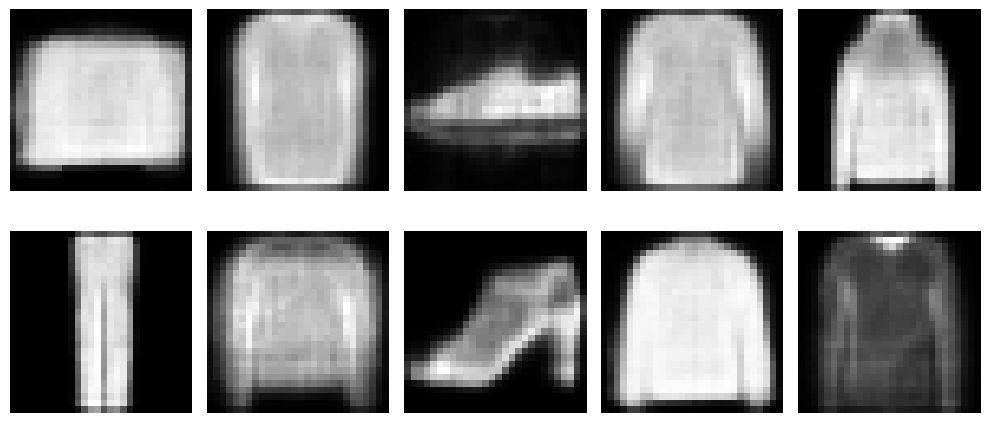

In [40]:
vae.eval()

with torch.no_grad():
  z = torch.randn(100, latent_dim).to(device)
  generated_images = vae.decoder(z)
  generated_images = generated_images.view(-1, 1, 28, 28)

plt.figure(figsize=(10,5))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(generated_images[i].cpu().squeeze(), cmap="gray")
  plt.axis("off")

plt.tight_layout()
plt.show()

**GAN**

In [41]:
latent_dim = 100
lr = 0.0002
epoch = 25

In [42]:
class Generator(nn.Module):
  def __init__(self):
    super(Generator, self).__init__()
    self.model = nn.Sequential(
        nn.Linear(latent_dim, 256),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Linear(256, 512),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Linear(512, 1024),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Linear(1024, 784),
        nn.Tanh()
    )
  def forward(self, z):
    img = self.model(z)
    img = img.view(img.size(0), 1, 28, 28)
    return img

class Discriminator(nn.Module):
  def __init__(self):
    super(Discriminator, self).__init__()
    self.model = nn.Sequential(
        nn.Linear(784, 1024),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Dropout(0.3),
        nn.Linear(1024, 512),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Dropout(0.3),
        nn.Linear(512, 256),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Dropout(0.3),
        nn.Linear(256, 1),
        nn.Sigmoid()
    )
  def forward(self, img):
      img_flat = img.view(img.size(0), -1)
      validity = self.model(img_flat)
      return validity

In [43]:
generator = Generator().to(device)
discriminator = Discriminator().to(device)
print(generator)
print(discriminator)

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2, inplace=True)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=True)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, 

In [44]:
criterion = nn.BCELoss()

optimizer_g = optim.Adam(generator.parameters(), lr=lr)
optimizer_d = optim.Adam(discriminator.parameters(), lr=lr)

In [45]:
g_losses = []
d_losses = []

for e in range(epochs):
  g_epoch_loss = 0
  d_epoch_loss = 0
  for i, (images, _) in enumerate(train_loader):
    images = images.to(device)
    batch_size = images.size(0)

    real_labels = torch.ones(batch_size, 1).to(device)
    fake_labels = torch.zeros(batch_size, 1).to(device)

    optimizer_g.zero_grad()
    z = torch.randn(batch_size, latent_dim).to(device)
    generated_images = generator(z)
    loss_g = criterion(discriminator(generated_images), real_labels)
    loss_g.backward()
    optimizer_g.step()

    optimizer_d.zero_grad()
    real_loss = criterion(discriminator(images), real_labels)
    fake_loss = criterion(discriminator(generated_images.detach()), fake_labels)
    loss_d = (real_loss + fake_loss) / 2
    loss_d.backward()
    optimizer_d.step()

    g_epoch_loss += loss_g.item()
    d_epoch_loss += loss_d.item()
  g_losses.append(g_epoch_loss / len(train_loader))
  d_losses.append(d_epoch_loss / len(train_loader))
  print(f"Epoch [{e+1}/{epochs}] G Loss: {g_epoch_loss/len(train_loader):.4f} D Loss: {d_epoch_loss/len(train_loader):.4f}")

Epoch [1/20] G Loss: 1.6259 D Loss: 0.5305
Epoch [2/20] G Loss: 1.2317 D Loss: 0.5970
Epoch [3/20] G Loss: 1.2646 D Loss: 0.4179
Epoch [4/20] G Loss: 1.1878 D Loss: 0.5036
Epoch [5/20] G Loss: 1.4317 D Loss: 0.4903
Epoch [6/20] G Loss: 1.2567 D Loss: 0.4982
Epoch [7/20] G Loss: 1.3049 D Loss: 0.4572
Epoch [8/20] G Loss: 1.1588 D Loss: 0.5185
Epoch [9/20] G Loss: 1.3982 D Loss: 0.4208
Epoch [10/20] G Loss: 1.4810 D Loss: 0.4589
Epoch [11/20] G Loss: 1.4230 D Loss: 0.4357
Epoch [12/20] G Loss: 1.6854 D Loss: 0.4332
Epoch [13/20] G Loss: 1.3270 D Loss: 0.4612
Epoch [14/20] G Loss: 1.5475 D Loss: 0.4387
Epoch [15/20] G Loss: 1.5023 D Loss: 0.4254
Epoch [16/20] G Loss: 1.4181 D Loss: 0.4307
Epoch [17/20] G Loss: 1.6204 D Loss: 0.4313
Epoch [18/20] G Loss: 1.6812 D Loss: 0.4580
Epoch [19/20] G Loss: 1.7153 D Loss: 0.4549
Epoch [20/20] G Loss: 1.5427 D Loss: 0.4151


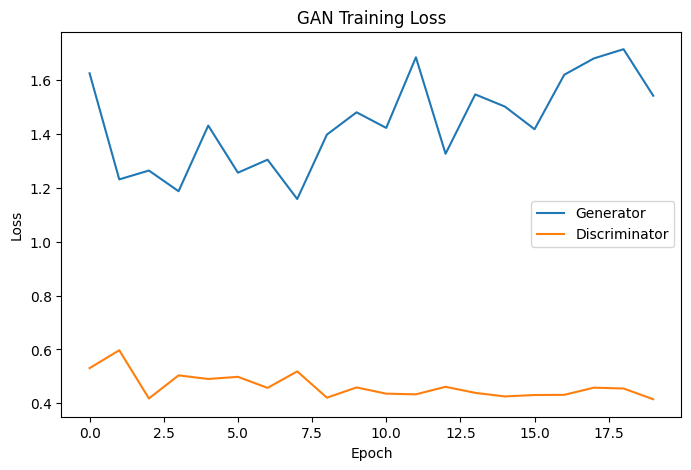

In [46]:
plt.figure(figsize=(8,5))
plt.plot(g_losses, label="Generator")
plt.plot(d_losses, label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.show()

In [47]:
generator.eval()
with torch.no_grad():
    noise = torch.randn(16,latent_dim).to(device)
    generated_images = generator(noise)

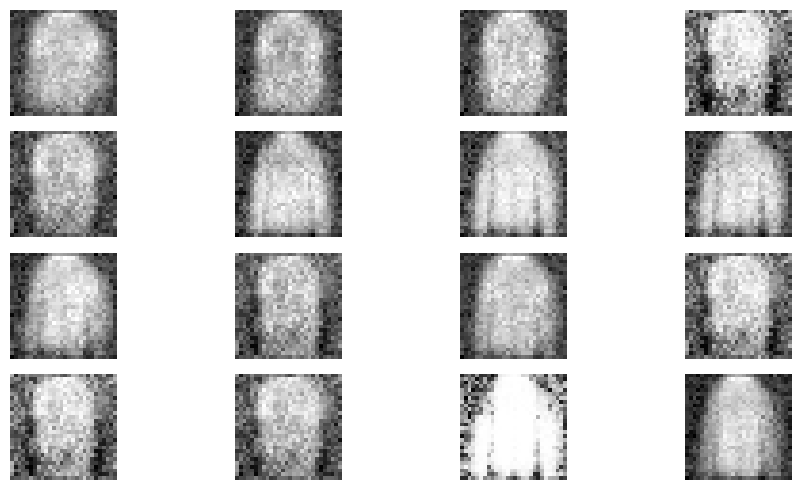

In [48]:
plt.figure(figsize=(10,5))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated_images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [49]:
torch.save(generator.state_dict(),"gan_generator.pth")
torch.save(discriminator.state_dict(), "gan_discriminator.pth")
print("GAN saved!")

GAN saved!


**DCGAN**

In [50]:
latent_dim = 100
lr = 0.0002
epochs = 20
image_size = 28

In [51]:
class DCGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # Input: (batch_size, 100, 1, 1)
            nn.ConvTranspose2d(100, 256, kernel_size=7, stride=1, padding=0),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # State: (batch_size, 256, 7, 7)
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # State: (batch_size, 128, 14, 14)
            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1), # Changed padding from 3 to 1 to yield 28x28
            nn.Tanh()
            # Output: (batch_size, 1, 28, 28)
        )

    def forward(self, z):
        return self.model(z)

In [52]:
class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # Input: (batch_size, 1, 28, 28)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (batch_size, 64, 14, 14)
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (batch_size, 128, 7, 7)
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

In [53]:
dc_generator = DCGenerator().to(device)

dc_discriminator = DCDiscriminator().to(device)

print(dc_generator)
print(dc_discriminator)

DCGenerator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)
DCDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten(start_dim=1, end_dim=-1)
    (

In [54]:
# Re-instantiate the updated models on the device
dc_generator = DCGenerator().to(device)
dc_discriminator = DCDiscriminator().to(device)

# Set loss function
criterion = nn.BCELoss()

# Configure Adam optimizers with the updated model parameters
optimizer_G = optim.Adam(dc_generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = optim.Adam(dc_discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

print("Models and optimizers successfully re-initialized with matching 28x28 shapes!")

Models and optimizers successfully re-initialized with matching 28x28 shapes!


In [55]:
dc_g_losses = []
dc_d_losses = []

for epoch in range(epochs):

    g_epoch_loss = 0
    d_epoch_loss = 0

    for real_imgs, _ in train_loader:
        real_imgs = real_imgs.to(device)
        batch_size = real_imgs.size(0)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        optimizer_D.zero_grad()

        real_output = dc_discriminator(real_imgs)
        d_real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, latent_dim, 1, 1).to(device)

        fake_imgs = dc_generator(noise)
        fake_output = dc_discriminator(fake_imgs.detach())

        d_fake_loss = criterion(fake_output, fake_labels)
        d_loss = (d_real_loss + d_fake_loss)
        d_loss.backward()
        optimizer_D.step()

        optimizer_G.zero_grad()

        noise = torch.randn(batch_size, latent_dim, 1, 1).to(device)

        generated_imgs = dc_generator(noise)

        output = dc_discriminator(generated_imgs)

        g_loss = criterion(output, real_labels)

        g_loss.backward()

        optimizer_G.step()

        g_epoch_loss += g_loss.item()
        d_epoch_loss += d_loss.item()

    dc_g_losses.append(g_epoch_loss / len(train_loader))

    dc_d_losses.append(d_epoch_loss / len(train_loader))

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"D Loss: {dc_d_losses[-1]:.4f} "
        f"G Loss: {dc_g_losses[-1]:.4f} "
    )

Epoch [1/20] D Loss: 0.5254 G Loss: 2.1369 
Epoch [2/20] D Loss: 0.2918 G Loss: 2.7065 
Epoch [3/20] D Loss: 0.2053 G Loss: 3.2811 
Epoch [4/20] D Loss: 0.1523 G Loss: 3.9632 
Epoch [5/20] D Loss: 0.1173 G Loss: 4.3013 
Epoch [6/20] D Loss: 0.1331 G Loss: 4.3636 
Epoch [7/20] D Loss: 0.0758 G Loss: 4.8266 
Epoch [8/20] D Loss: 0.1382 G Loss: 4.6046 
Epoch [9/20] D Loss: 0.0899 G Loss: 4.9921 
Epoch [10/20] D Loss: 0.0898 G Loss: 5.1787 
Epoch [11/20] D Loss: 0.0931 G Loss: 4.9092 
Epoch [12/20] D Loss: 0.0948 G Loss: 5.1033 
Epoch [13/20] D Loss: 0.0537 G Loss: 5.6136 
Epoch [14/20] D Loss: 0.1520 G Loss: 4.6566 
Epoch [15/20] D Loss: 0.1005 G Loss: 4.8014 
Epoch [16/20] D Loss: 0.0767 G Loss: 5.9735 
Epoch [17/20] D Loss: 0.0770 G Loss: 4.6826 
Epoch [18/20] D Loss: 0.0299 G Loss: 6.0018 
Epoch [19/20] D Loss: 0.1489 G Loss: 5.6960 
Epoch [20/20] D Loss: 0.1131 G Loss: 4.7340 


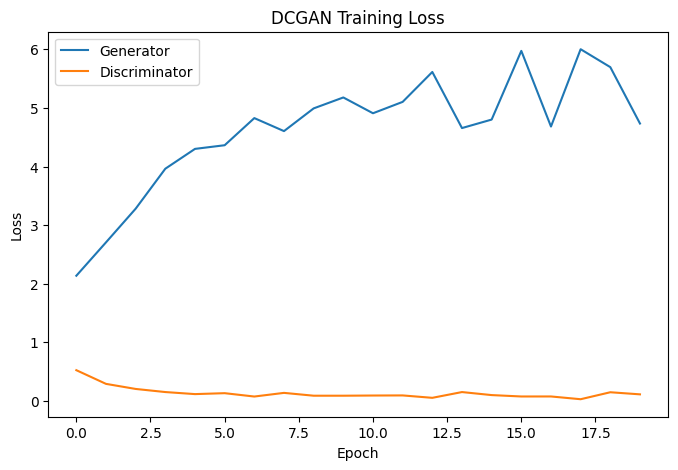

In [56]:
plt.figure(figsize=(8,5))
plt.plot(dc_g_losses, label="Generator")
plt.plot(dc_d_losses, label="Discriminator")
plt.title("DCGAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [57]:
dc_generator.eval()

with torch.no_grad():
    noise = torch.randn(16, latent_dim, 1, 1).to(device)
    generated_imgs = dc_generator(noise)

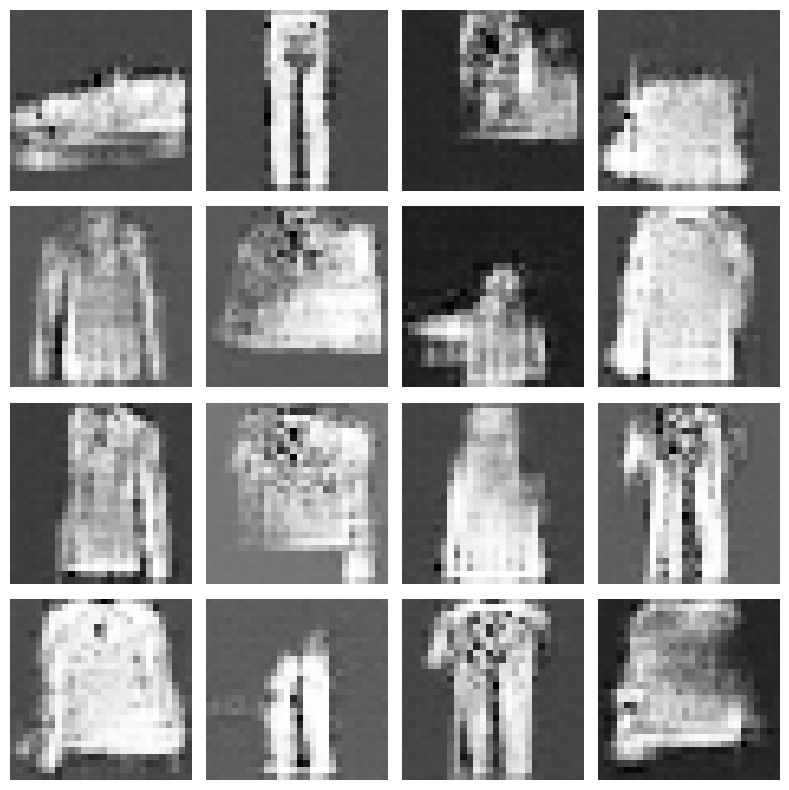

In [58]:
plt.figure(figsize=(8,8))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated_imgs[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [59]:
torch.save(
    dc_generator.state_dict(),
    "dcgan_generator.pth"
)

torch.save(
    dc_discriminator.state_dict(),
    "dcgan_discriminator.pth"
)

print("DCGAN Saved!")

DCGAN Saved!


**DDPM**

In [60]:
IMAGE_SIZE = 28
CHANNELS = 1

BATCH_SIZE = 128

TIMESTEPS = 100

EPOCHS = 20

LR = 1e-3

In [61]:
beta_start = 1e-4
beta_end = 0.02

betas = torch.linspace(beta_start, beta_end, TIMESTEPS).to(device)

alphas = 1. - betas

alpha_bars = torch.cumprod(alphas, dim=0)

In [62]:
def forward_diffusion_sample(x0, t):

    noise = torch.randn_like(x0)
    alpha_bar_t = alpha_bars[t]

    sqrt_alpha_bar = torch.sqrt(alpha_bar_t).view(-1,1,1,1)
    sqrt_one_minus_alpha_bar = torch.sqrt(1 - alpha_bar_t).view(-1,1,1,1)

    noisy_image = (sqrt_alpha_bar * x0 + sqrt_one_minus_alpha_bar * noise)

    return noisy_image, noise

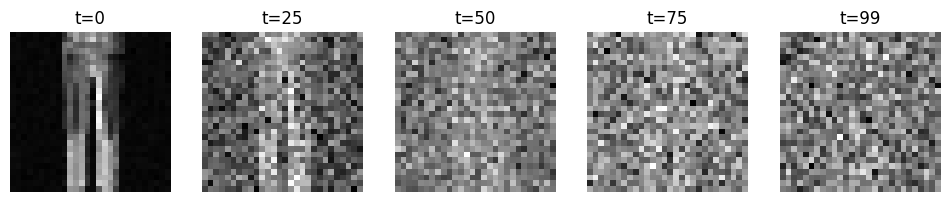

In [63]:
sample, _ = next(iter(train_loader))
sample = sample[:1].to(device)

# Changed steps to remain within [0, TIMESTEPS-1] (0 to 99)
steps = [0, 25, 50, 75, 99]

plt.figure(figsize=(12,3))

for i, t in enumerate(steps):
    t_tensor = torch.tensor([t]).to(device)
    noisy, _ = forward_diffusion_sample(sample, t_tensor)

    plt.subplot(1,5,i+1)
    plt.imshow(noisy[0].cpu().squeeze(), cmap="gray")
    plt.title(f"t={t}")
    plt.axis("off")

plt.show()

In [64]:
class SimpleDDPM(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, 3, padding=1)
        )

    def forward(self, x, t):
        return self.net(x)

In [65]:
ddpm = SimpleDDPM().to(device)

optimizer_ddpm = optim.Adam(ddpm.parameters(), lr=LR)

criterion = nn.MSELoss()


In [66]:
def train_ddpm_epoch():
    ddpm.train()
    total_loss = 0

    for images,_ in train_loader:
        images = images.to(device)

        t = torch.randint(0, TIMESTEPS, (images.shape[0],), device=device)

        noisy_images, noise = (forward_diffusion_sample(images, t))

        predicted_noise = ddpm(noisy_images, t)
        loss = criterion(predicted_noise, noise)

        optimizer_ddpm.zero_grad()
        loss.backward()
        optimizer_ddpm.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)

In [67]:
ddpm_losses = []

for epoch in range(EPOCHS):
    loss = train_ddpm_epoch()
    ddpm_losses.append(loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
        f" | Loss: {loss:.5f}"
    )

Epoch 1/20 | Loss: 0.21133
Epoch 2/20 | Loss: 0.13650
Epoch 3/20 | Loss: 0.12565
Epoch 4/20 | Loss: 0.12046
Epoch 5/20 | Loss: 0.11708
Epoch 6/20 | Loss: 0.11528
Epoch 7/20 | Loss: 0.11363
Epoch 8/20 | Loss: 0.11154
Epoch 9/20 | Loss: 0.11119
Epoch 10/20 | Loss: 0.10929
Epoch 11/20 | Loss: 0.10797
Epoch 12/20 | Loss: 0.10887
Epoch 13/20 | Loss: 0.10770
Epoch 14/20 | Loss: 0.10773
Epoch 15/20 | Loss: 0.10685
Epoch 16/20 | Loss: 0.10638
Epoch 17/20 | Loss: 0.10555
Epoch 18/20 | Loss: 0.10523
Epoch 19/20 | Loss: 0.10490
Epoch 20/20 | Loss: 0.10544


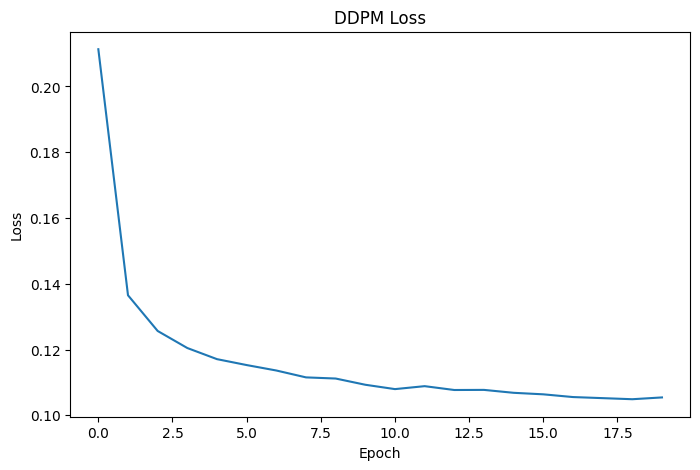

In [68]:
plt.figure(figsize=(8,5))
plt.plot(ddpm_losses)
plt.title("DDPM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()


In [69]:
@torch.no_grad()
def sample_ddpm(model, n=16):
    model.eval()
    x = torch.randn(n, 1, 28, 28).to(device)

    for t in reversed(range(TIMESTEPS)):
        predicted_noise = model(x, torch.tensor([t], device=device))

        x = x - (betas[t] * predicted_noise)

    return x

In [70]:
generated = sample_ddpm(ddpm, 16)

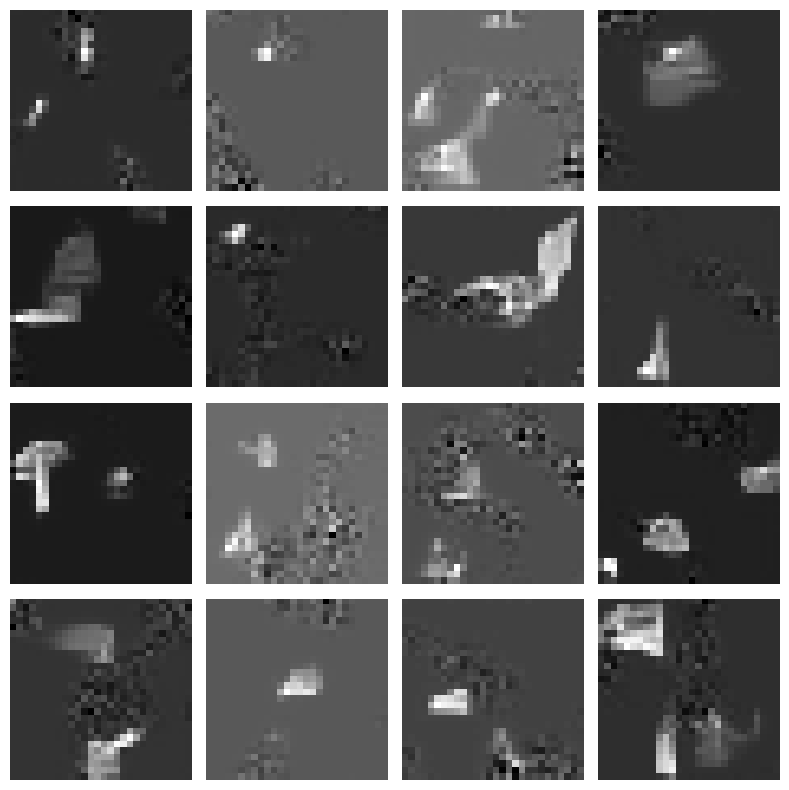

In [71]:
plt.figure(figsize=(8,8))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()

plt.show()

In [72]:
torch.save(ddpm.state_dict(), "ddpm_model.pth")

print("DDPM saved!")

DDPM saved!


MLP

In [73]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784,256)
        self.fc2 = nn.Linear(256,64)
        self.fc3 = nn.Linear(64,10)
        self.relu = nn.ReLU()

    def forward(self,x):
        x = self.flatten(x)
        h1 = self.relu(self.fc1(x))
        z = self.relu(self.fc2(h1))

        logits = self.fc3(z)

        return logits,z

**tahap 1**

In [77]:
# Instantiate the model first
mlp = MLPClassifier().to(device)

W1 = mlp.fc1.weight.detach().cpu()
W2 = mlp.fc2.weight.detach().cpu()
W3 = mlp.fc3.weight.detach().cpu()

print(W1.shape)
print(W2.shape)
print(W3.shape)

torch.Size([256, 784])
torch.Size([64, 256])
torch.Size([10, 64])


In [83]:
images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():

    logits, z_mlp = mlp(images)

print(z_mlp.shape)

torch.Size([128, 64])


**tahap 2**

In [85]:
target_class = 0

y = torch.zeros(1, 10)
y[0, target_class] = 1

with torch.no_grad():
    # W3 shape is [10, 64], so y @ W3 yields [1, 64]
    z_hat = torch.relu(y @ W3)
    # W2 shape is [64, 256], so z_hat @ W2 yields [1, 256]
    h_hat = torch.relu(z_hat @ W2)
    # W1 shape is [256, 784], so h_hat @ W1 yields [1, 784]
    x_hat = torch.relu(h_hat @ W1)

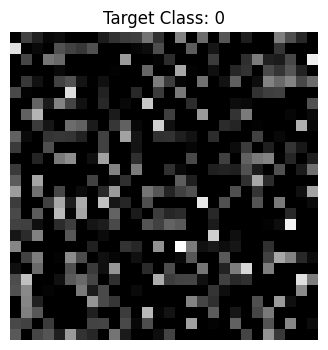

In [88]:
plt.figure(figsize=(4,4))
plt.imshow(x_hat[0].cpu().squeeze().view(28, 28), cmap="gray")
plt.axis("off")
plt.title(f"Target Class: {target_class}")
plt.show()

**tahap 3**

In [89]:
images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    _, z_mlp = mlp(images)

In [90]:
sample_z = z_mlp[0:1].cpu()

with torch.no_grad():
    h_hat = torch.relu(sample_z @ W2)
    x_hat = torch.sigmoid(h_hat @ W1)

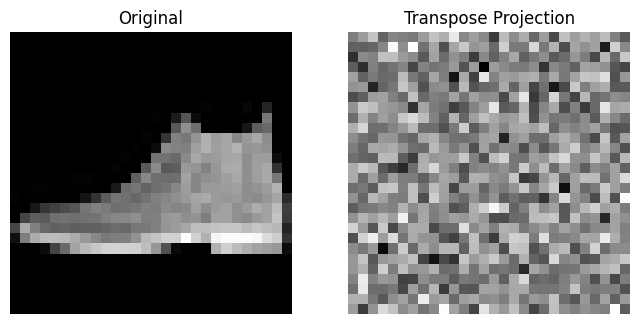

In [91]:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)

plt.imshow(images[0].cpu().squeeze(), cmap="gray")

plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(x_hat.reshape(28,28), cmap="gray")

plt.title("Transpose Projection")
plt.axis("off")

plt.show()

**tahap 4**

In [92]:
for param in mlp.parameters():
    param.requires_grad = False

In [93]:
class FrozenDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Linear(64,256),
            nn.ReLU(),
            nn.Linear(256,784),
            nn.Sigmoid()
        )

    def forward(self,z):
        reconstruction = self.decoder(z)
        return reconstruction.view(-1, 1, 28, 28)

In [94]:
decoder = FrozenDecoder().to(device)

criterion = nn.MSELoss()

optimizer_decoder = optim.Adam(decoder.parameters(), lr=1e-3)

In [95]:
epochs = 20

decoder_losses = []

for epoch in range(epochs):

    decoder.train()

    total_loss = 0

    for images,_ in train_loader:
        images = images.to(device)

        with torch.no_grad():
            _, z = mlp(images)

        reconstruction = decoder(z)
        loss = criterion(reconstruction, images)
        optimizer_decoder.zero_grad()
        loss.backward()
        optimizer_decoder.step()
        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)

    decoder_losses.append(epoch_loss)

    print(
        f"Epoch {epoch+1}: "
        f"{epoch_loss:.5f}"
    )

Epoch 1: 0.06365
Epoch 2: 0.03497
Epoch 3: 0.03017
Epoch 4: 0.02783
Epoch 5: 0.02625
Epoch 6: 0.02502
Epoch 7: 0.02402
Epoch 8: 0.02319
Epoch 9: 0.02250
Epoch 10: 0.02193
Epoch 11: 0.02145
Epoch 12: 0.02104
Epoch 13: 0.02069
Epoch 14: 0.02038
Epoch 15: 0.02010
Epoch 16: 0.01985
Epoch 17: 0.01963
Epoch 18: 0.01943
Epoch 19: 0.01924
Epoch 20: 0.01907


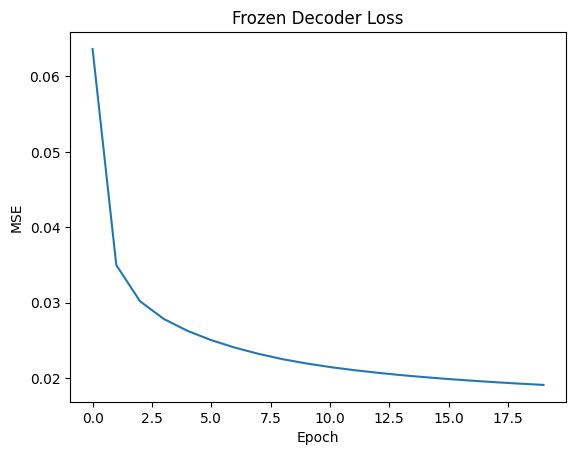

In [96]:
plt.plot(decoder_losses)
plt.title("Frozen Decoder Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

In [97]:
decoder.eval()

images,_ = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    _, z = mlp(images)
    reconstruction = decoder(z)

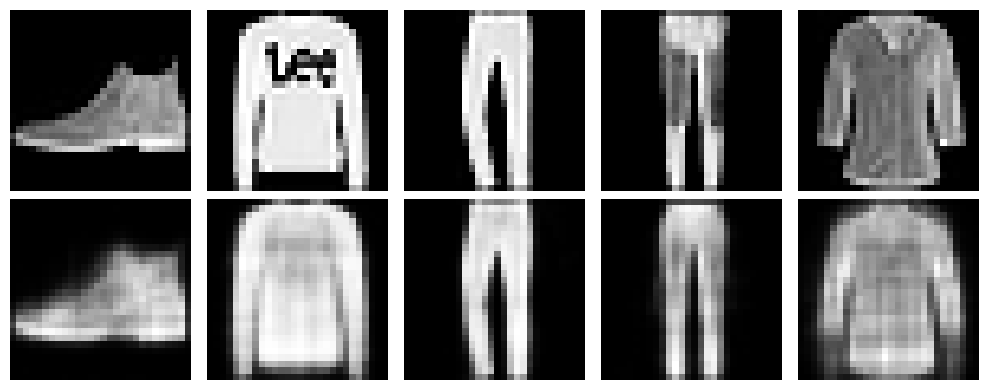

In [98]:
plt.figure(figsize=(10,4))

for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    plt.subplot(2,5,i+6)
    plt.imshow(reconstruction[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

**tahap 5**

In [99]:
latent_list = []

with torch.no_grad():
    for images,_ in test_loader:
        images = images.to(device)
        _, z = mlp(images)
        latent_list.append(z.cpu())

latent_all = torch.cat(latent_list, dim=0)
print(latent_all.shape)

torch.Size([10000, 64])


In [100]:
mu = latent_all.mean(dim=0)
sigma = latent_all.std(dim=0)

z_rand = torch.normal(mu, sigma)
z_rand = z_rand.unsqueeze(0).to(device)

decoder.eval()
with torch.no_grad():
    generated = decoder(z_rand)

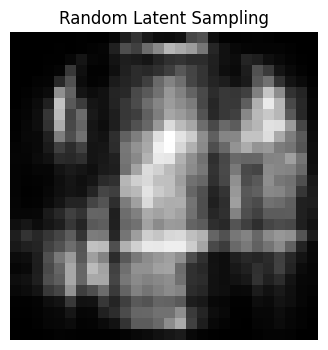

In [101]:
plt.figure(figsize=(4,4))
plt.imshow(generated[0].cpu().squeeze(), cmap="gray")
plt.title("Random Latent Sampling")
plt.axis("off")
plt.show()

**Evaluasi MSE, PSNR, SSIM**

In [102]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.metrics import mean_squared_error
import numpy as np

In [103]:
def calculate_metrics(originals, reconstructions):
    mse_list = []
    psnr_list = []
    ssim_list = []

    originals = originals.cpu().numpy()
    reconstructions = reconstructions.cpu().numpy()

    for i in range(len(originals)):
        original = originals[i].squeeze()
        reconstructed = (reconstructions[i].squeeze())
        mse = mean_squared_error(original.flatten(), reconstructed.flatten())
        psnr = peak_signal_noise_ratio(original, reconstructed, data_range= 1.0)
        ssim = structural_similarity(original, reconstructed, data_range= 1.0)

        mse_list.append(mse)
        psnr_list.append(psnr)
        ssim_list.append(ssim)

    return (np.mean(mse_list), np.mean(psnr_list), np.mean(ssim_list))

In [104]:
ae.eval()

images,_ = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    ae_recon = ae(images)

ae_mse, ae_psnr, ae_ssim = (calculate_metrics(images.cpu(), ae_recon.cpu()))

print("AE Results")
print("MSE :", ae_mse)
print("PSNR:", ae_psnr)
print("SSIM:", ae_ssim)

AE Results
MSE : 0.009722389691887656
PSNR: 21.00598060559947
SSIM: 0.7568689060126867


In [105]:
decoder.eval()

with torch.no_grad():
    _, z = mlp(images)
    decoder_recon = decoder(z)

fd_mse, fd_psnr, fd_ssim = (calculate_metrics(images.cpu(), decoder_recon.cpu()))

print("Frozen Decoder Results")
print("MSE :", fd_mse)
print("PSNR:", fd_psnr)
print("SSIM:", fd_ssim)

Frozen Decoder Results
MSE : 0.017992814733588602
PSNR: 18.072724921013616
SSIM: 0.6103989261423239


In [107]:
import pandas as pd

results = pd.DataFrame({
    "Model":["Vanilla AE", "Frozen Decoder"],
    "MSE":[ae_mse, fd_mse],
    "PSNR":[ae_psnr, fd_psnr],
    "SSIM":[ae_ssim, fd_ssim]
})

results

,Model,MSE,PSNR,SSIM
0,Vanilla AE,0.009722,21.005981,0.756869
1,Frozen Decoder,0.017993,18.072725,0.610399


**FID**

In [123]:
!pip install pytorch-fid

In [125]:
import os
import torchvision.utils as vutils

os.makedirs("real_images", exist_ok=True)
count = 0
for images, _ in test_loader:
    for img in images:
        vutils.save_image(img, f"real_images/{count}.png")
        count += 1
        if count >= 1000:
            break

    if count >= 1000:
        break

print("Done")

Done


In [126]:
os.makedirs("gan_images", exist_ok=True)
generator.eval()
count = 0

with torch.no_grad():
    while count < 1000:
        z = torch.randn( 32, latent_dim).to(device)
        fake_imgs = generator(z)
        fake_imgs = (fake_imgs + 1) / 2

        for img in fake_imgs:
            vutils.save_image(img, f"gan_images/{count}.png")
            count += 1
            if count >= 1000:
                break

In [127]:
os.makedirs("dcgan_images", exist_ok=True)

dc_generator.eval()

count = 0

with torch.no_grad():
    while count < 1000:
        z = torch.randn(32, latent_dim, 1, 1).to(device)
        fake_imgs = dc_generator(z)
        fake_imgs = (fake_imgs + 1) / 2

        for img in fake_imgs:
            vutils.save_image(img, f"dcgan_images/{count}.png")
            count += 1
            if count >= 1000:
                break

In [128]:
os.makedirs("ddpm_images", exist_ok=True)

count = 0

while count < 1000:
    imgs = sample_ddpm(ddpm, n=16)
    imgs = torch.clamp(imgs, 0, 1)
    for img in imgs:
        vutils.save_image(img, f"ddpm_images/{count}.png")
        count += 1
        if count >= 1000:
            break

In [135]:
print(os.path.exists("real_images"))
print(os.path.exists("gan_images"))
print(os.path.exists("dcgan_images"))
print(os.path.exists("ddpm_images"))

import os

print(os.getcwd())
print(os.listdir())

print(len(os.listdir("real_images")))

True
True
True
True
/content
['.config', 'gan_discriminator.pth', 'dcgan_generator.pth', 'data', 'gan_images', 'gan_generator.pth', 'ddpm_images', 'ddpm_model.pth', 'dcgan_images', 'real_images', 'dcgan_discriminator.pth', 'vanilla_autoencoder.pth', 'sample_data']
1000


In [136]:
import os

for folder in [
    "real_images",
    "gan_images",
    "dcgan_images",
    "ddpm_images"
]:
    print(folder)

    if os.path.exists(folder):
        print("Exists")

        print(
            "Files:",
            len(os.listdir(folder))
        )

    else:
        print("NOT FOUND")

    print("-"*30)

real_images
Exists
Files: 1000
------------------------------
gan_images
Exists
Files: 1000
------------------------------
dcgan_images
Exists
Files: 1000
------------------------------
ddpm_images
Exists
Files: 1000
------------------------------


In [137]:
!python -m pytorch_fid real_images gan_images

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
100% 91.2M/91.2M [00:00<00:00, 297MB/s]
100% 20/20 [04:01<00:00, 12.07s/it]
100% 20/20 [04:07<00:00, 12.35s/it]
FID:  307.91149221221497


In [138]:
!python -m pytorch_fid real_images dcgan_images

100% 20/20 [04:21<00:00, 13.10s/it]
100% 20/20 [04:11<00:00, 12.59s/it]
FID:  130.24022762253549


In [139]:
!python -m pytorch_fid real_images ddpm_images

100% 20/20 [04:03<00:00, 12.18s/it]
100% 20/20 [04:10<00:00, 12.51s/it]
FID:  207.96686597206957


In [140]:
fid_gan = 307.91
fid_dcgan = 130.24
fid_ddpm = 207.96

In [141]:
import pandas as pd

fid_results = pd.DataFrame({

    "Model":[
        "GAN",
        "DCGAN",
        "DDPM"
    ],

    "FID":[
        fid_gan,
        fid_dcgan,
        fid_ddpm
    ]
})

fid_results

,Model,FID
0,GAN,307.91
1,DCGAN,130.24
2,DDPM,207.96


**Latent Interpolation**

In [142]:
images, labels = next(iter(test_loader))

img1 = images[0:1].to(device)
img2 = images[1:2].to(device)

In [143]:
ae.eval()

with torch.no_grad():
    z1 = ae.encoder(img1)
    z2 = ae.encoder(img2)

alphas = torch.linspace(0, 1, 10).to(device)
interpolations = []

with torch.no_grad():
    for alpha in alphas:
        z = ((1-alpha) * z1 + alpha * z2)
        reconstructed = ae.decoder(z)
        reconstructed = reconstructed.view(1, 1, 28, 28)

        interpolations.append(reconstructed.cpu())

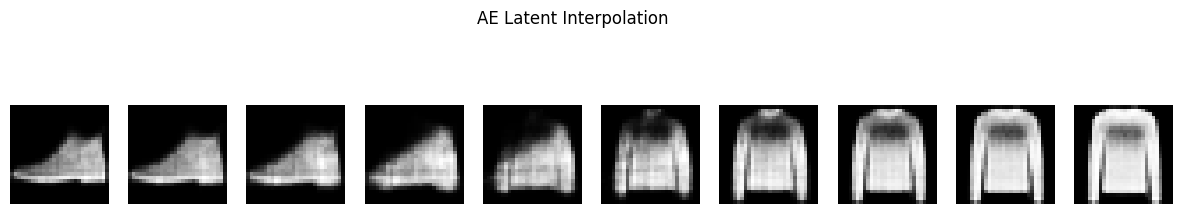

In [144]:
plt.figure(figsize=(15,3))

for i,img in enumerate(interpolations):
    plt.subplot(1,10,i+1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("AE Latent Interpolation")

plt.show()

In [145]:
sae.eval()

with torch.no_grad():
    _, z1 = sae(img1)
    _, z2 = sae(img2)

interpolations_sae = []

with torch.no_grad():

    for alpha in alphas:
        z = ((1-alpha) * z1 + alpha * z2)
        reconstructed = sae.decoder(z)
        reconstructed = reconstructed.view(1, 1, 28, 28)

        interpolations_sae.append(reconstructed.cpu())


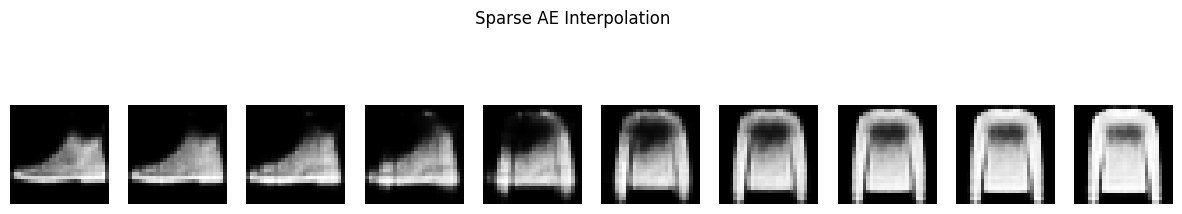

In [146]:
plt.figure(figsize=(15,3))
for i,img in enumerate(interpolations_sae):
    plt.subplot(1,10,i+1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("Sparse AE Interpolation")

plt.show()

In [147]:
vae.eval()

with torch.no_grad():
    h1 = vae.encoder(img1)
    mu1 = vae.fc_mu(h1)
    h2 = vae.encoder(img2)
    mu2 = vae.fc_mu(h2)

interpolations_vae = []

with torch.no_grad():
    for alpha in alphas:
        mu = ((1-alpha) * mu1 + alpha * mu2)
        z = vae.reparameterize(mu, torch.zeros_like(mu))
        reconstructed = vae.decoder(z)
        reconstructed = reconstructed.view(1, 1, 28, 28)

        interpolations_vae.append(reconstructed.cpu())

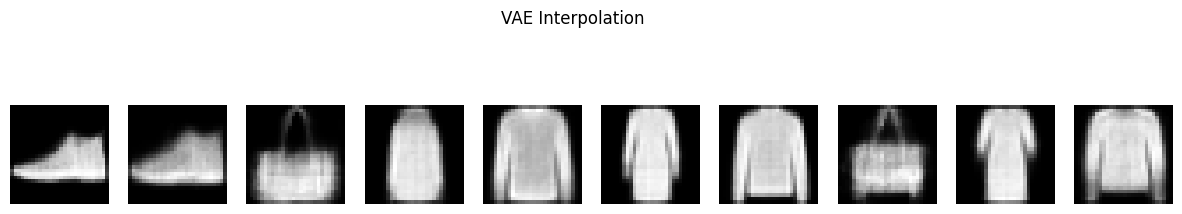

In [148]:
plt.figure(figsize=(15,3))
for i,img in enumerate(interpolations_vae):
    plt.subplot(1,10,i+1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("VAE Interpolation")

plt.show()

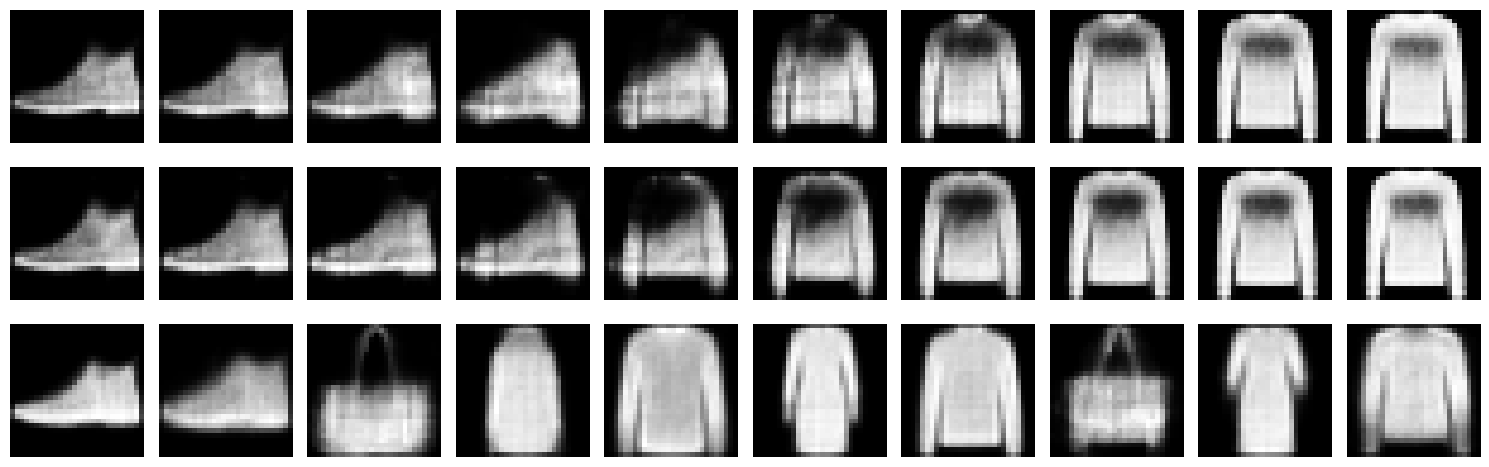

In [149]:
fig, axes = plt.subplots(3, 10, figsize=(15,5))
for i in range(10):
    axes[0,i].imshow(interpolations[i].squeeze(), cmap="gray")
    axes[1,i].imshow(interpolations_sae[i].squeeze(), cmap="gray")
    axes[2,i].imshow(interpolations_vae[i].squeeze(), cmap="gray")

    axes[0,i].axis("off")
    axes[1,i].axis("off")
    axes[2,i].axis("off")

axes[0,0].set_ylabel("AE")
axes[1,0].set_ylabel("Sparse AE")
axes[2,0].set_ylabel("VAE")

plt.tight_layout()

plt.show()